In [1]:
P = "/Volumes/workspace/default/dsmlc/"
daily = spark.read.parquet(P + "daily_production.parquet")
fail  = spark.read.parquet(P + "production_failures.parquet")
jobs  = spark.read.parquet(P + "well_jobs.parquet")

NameError: name 'spark' is not defined

In [0]:
print("daily:", daily.count())
print("failures:", fail.count())
print("jobs:", jobs.count())


daily: 5075590
failures: 2873
jobs: 15610


In [0]:
daily.select("uwi", "production_date", "flow_direction", "oil_produced_m3",
             "hours_on_prod", "primary_fluid_type", "field_operating_area").show(5)
jobs.select("uwi", "job_category", "start_date").show(5)

+----------------+---------------+--------------+------------------+-------------+------------------+--------------------+
|             uwi|production_date|flow_direction|   oil_produced_m3|hours_on_prod|primary_fluid_type|field_operating_area|
+----------------+---------------+--------------+------------------+-------------+------------------+--------------------+
|100142303701W400|     2021-07-04|    production|             11.32|         24.0|         Heavy Oil|           Bodo East|
|141092703528W300|     2021-05-24|     injection|              NULL|         24.0|           Polymer|         Cactus Lake|
|111152503528W300|     2021-06-28|    production|0.6606738382810681|         24.0|         Heavy Oil|         Cactus Lake|
|192031104225W300|     2021-03-25|    production| 2.527953159305913|         24.0|         Heavy Oil|              Winter|
|191063103527W300|     2021-05-10|    production|               0.0|          0.0|         Heavy Oil|         Cactus Lake|
+---------------

In [0]:
from pyspark.sql import functions as F
START = "2025-10-28"

oil = (daily
  .filter((F.col("flow_direction") == "production") & (F.col("production_date") >= START))
  .filter(~F.coalesce(F.col("primary_fluid_type"), F.lit("")).isin("Gas", "Water Source", "Polymer"))
  .groupBy("uwi")
  .agg(F.first("field_operating_area").alias("area"), F.sum("oil_produced_m3").alias("oil_m3"))
  .filter(F.col("oil_m3") > 0)
  .withColumn("bbl", F.col("oil_m3") * 6.2898))

print("oil wells:", oil.count())

oil wells: 1056


In [0]:
j = (jobs
  .filter((F.col("start_date") >= START) & F.col("job_category").isin("Rod Truck", "Workover"))
  .groupBy("uwi")
  .agg(F.sum((F.col("job_category") == "Rod Truck").cast("int")).alias("rod12"),
       F.sum((F.col("job_category") == "Workover").cast("int")).alias("wo12")))

wells = oil.join(j, "uwi", "left").fillna({"rod12": 0, "wo12": 0})
print("wells:", wells.count(), "| total bbl (M):", round(wells.agg(F.sum("bbl")).first()[0] / 1e6, 2))
print("rod jobs:", wells.agg(F.sum("rod12")).first()[0], "| workovers:", wells.agg(F.sum("wo12")).first()[0])

wells: 1056 | total bbl (M): 7.39
rod jobs: 1752 | workovers: 767


In [0]:
NETBACK, FIXED, ROD, WO = 40, 5000, 4000, 15000   # placeholder costs in C$

priced = wells.withColumn("net",
    F.col("bbl") * NETBACK - 12 * FIXED - F.col("rod12") * ROD - F.col("wo12") * WO)

In [0]:
losers = priced.filter(F.col("net") < 0)
n = losers.count()
loss = -losers.agg(F.sum("net")).first()[0]
share = losers.agg(F.sum("bbl")).first()[0] / priced.agg(F.sum("bbl")).first()[0]
print("losing wells:", n, "| annual loss C$M:", round(loss / 1e6, 2), "| share of oil %:", round(100 * share, 1))

losing wells: 193 | annual loss C$M: 7.56 | share of oil %: 2.3


In [0]:
priced.orderBy("net").select("uwi", "area", F.round("bbl").alias("bbl"), "rod12", "wo12", F.round("net").alias("net")).show(5)

+----------------+-----------+------+-----+----+---------+
|             uwi|       area|   bbl|rod12|wo12|      net|
+----------------+-----------+------+-----+----+---------+
|102141703528W300|Cactus Lake|1338.0|    8|   5|-113484.0|
|111100903627W300|Cactus Lake| 258.0|    3|   2| -91685.0|
|192063304225W300|     Winter|  17.0|    0|   2| -89326.0|
|195032803528W300|Cactus Lake| 155.0|    0|   2| -83800.0|
|101121803528W300|Cactus Lake| 203.0|    0|   2| -81875.0|
+----------------+-----------+------+-----+----+---------+
only showing top 5 rows


In [0]:
total_bbl = wells.agg(F.sum("bbl")).first()[0]
rows = []
for nb in (25, 40, 60):                 # oil price per barrel, C$
    for fx in (3000, 5000, 8000):       # fixed cost per well per month, C$
        net = F.col("bbl") * nb - 12 * fx - F.col("rod12") * ROD - F.col("wo12") * WO
        neg = wells.filter(net < 0)
        r = neg.agg(F.count("*").alias("n"), F.sum("bbl").alias("bbl"), F.sum(net).alias("net")).first()
        rows.append((nb, fx, r["n"], round(100 * r["bbl"] / total_bbl, 1), round(-r["net"] / 1e6, 1)))

grid = spark.createDataFrame(rows, ["netback", "fixed_per_month", "wells_negative", "pct_of_oil", "annual_loss_C_M"])
grid.show()

+-------+---------------+--------------+----------+---------------+
|netback|fixed_per_month|wells_negative|pct_of_oil|annual_loss_C_M|
+-------+---------------+--------------+----------+---------------+
|     25|           3000|           212|       3.1|            5.6|
|     25|           5000|           320|       6.9|           11.8|
|     25|           8000|           474|      14.5|           26.4|
|     40|           3000|           135|       1.0|            3.6|
|     40|           5000|           193|       2.3|            7.6|
|     40|           8000|           291|       5.5|           16.1|
|     60|           3000|            90|       0.3|            2.7|
|     60|           5000|           130|       0.9|            5.5|
|     60|           8000|           188|       2.1|           11.2|
+-------+---------------+--------------+----------+---------------+



Days the well was broken

In [0]:
from pyspark.sql import Window

down = (daily
  .filter((F.col("flow_direction") == "production") & (F.col("production_date") >= "2021-10-01")
          & (F.coalesce(F.col("hours_on_prod"), F.lit(0)) < 12))
  .select("uwi", "production_date", "field_operating_area", "downtime_code_1"))
print("down well-days:", down.count())

down well-days: 1379533


In [0]:
w = Window.partitionBy("uwi").orderBy("production_date")
down = (down.withColumn("rn", F.row_number().over(w))
            .withColumn("grp", F.expr("date_sub(production_date, rn)")))

bd = (down.groupBy("uwi", "grp")
  .agg(F.min("production_date").alias("s"), F.max("production_date").alias("e"),
       F.count("*").alias("n"), F.first("field_operating_area").alias("area"),
       F.mode("downtime_code_1").alias("cause")))
print("all breakdowns:", bd.count())

bd = bd.filter((F.col("s") >= "2022-01-01") & F.col("cause").rlike("(?i)downhole|rod|pump|tubing"))
print("equipment breakdowns since 2022:", bd.count())

all breakdowns: 20365
equipment breakdowns since 2022: 9035


In [0]:
jb = (jobs.filter(F.col("job_category").isin("Rod Truck", "Workover"))
  .groupBy("uwi", F.col("start_date").alias("sd"))
  .agg(F.max((F.col("job_category") == "Workover").cast("int")).alias("is_wo"))
  .withColumn("jtype", F.when(F.col("is_wo") == 1, "Workover").otherwise("Rod Truck")))

m = (bd.join(jb, "uwi")
  .filter((F.col("sd") >= F.col("s")) & (F.col("sd") <= F.date_add(F.col("e"), 1)))
  .withColumn("rk", F.row_number().over(Window.partitionBy("uwi", "s").orderBy("sd")))
  .filter(F.col("rk") == 1))
print("matched to a job:", m.count())

matched to a job: 7516


In [0]:
prod = (daily.filter((F.col("flow_direction") == "production") & (F.coalesce(F.col("hours_on_prod"), F.lit(0)) >= 12))
        .select("uwi", F.col("production_date").alias("d"), "oil_produced_m3"))

rate = (m.select("uwi", "s").join(prod, "uwi")
  .filter((F.col("d") >= F.date_sub(F.col("s"), 30)) & (F.col("d") < F.col("s")))
  .groupBy("uwi", "s").agg(F.avg("oil_produced_m3").alias("rate")))

In [0]:
ep = (m.join(rate, ["uwi", "s"])
  .filter(F.col("rate") > 0)
  .withColumn("wait", F.datediff(F.col("sd"), F.col("s")))
  .withColumn("lost_bbl", F.col("rate") * F.col("wait") * 6.2898))

ep.write.mode("overwrite").saveAsTable("workspace.default.breakdowns")
ep = spark.table("workspace.default.breakdowns")

st = ep.agg(F.count("*").alias("n"), F.sum("lost_bbl").alias("bbl"), F.avg("wait").alias("mean_wait"),
            F.expr("percentile(wait, 0.5)").alias("median_wait")).first()
print("breakdowns:", st["n"], "| lost bbl (k):", round(st["bbl"] / 1e3), "| median wait:", st["median_wait"], "| mean wait:", round(st["mean_wait"], 1))

breakdowns: 7452 | lost bbl (k): 526 | median wait: 2.0 | mean wait: 4.0


In [0]:
import pandas as pd

pdf = ep.select("uwi", "s", "sd", "area", "jtype", "rate", "wait").toPandas()
pdf["s"] = pd.to_datetime(pdf["s"])
pdf["sd"] = pd.to_datetime(pdf["sd"])
pdf["rate"] = pdf["rate"].astype(float)
print(len(pdf))

7452


In [0]:
def simulate(df, rule, cap=None):
    """Oil lost (bbl) while waiting, if the real crew visits are handed out by `rule`."""
    total = 0.0
    for _, g in df.groupby(["area", "jtype"]):          # crews only swap within an area and job type
        g = g.sort_values("s").reset_index(drop=True)
        start = g["s"].values.astype("datetime64[D]").astype(int)    # day the well broke down
        real  = g["sd"].values.astype("datetime64[D]").astype(int)   # day it was really fixed
        rate  = g["rate"].values                                     # oil it made before breaking
        waiting, nxt = [], 0
        for day in sorted(real):                         # each real job date is one crew visit
            while nxt < len(g) and start[nxt] <= day:    # wells broken down by this day
                waiting.append(nxt); nxt += 1
            if not waiting:
                continue
            pool = waiting
            if cap is not None:                          # deadline rule: nobody waits more than `cap`
                late = [k for k in waiting if day >= real[k] + cap]   # days longer than they really did
                pool = late if late else waiting
            if rule == "value":
                pick = max(pool, key=lambda k: (rate[k], -start[k]))  # most oil first
            else:
                pick = max(pool, key=lambda k: -start[k])             # longest waiting first
            waiting.remove(pick)
            total += rate[pick] * (day - start[pick])
    return total * 6.2898

In [0]:
actual = (pdf["rate"] * pdf["wait"]).sum() * 6.2898
runs = [("actual", actual),
        ("highest-oil-first, no limit", simulate(pdf, "value")),
        ("highest-oil-first, 14-day limit", simulate(pdf, "value", 14)),
        ("highest-oil-first, 7-day limit", simulate(pdf, "value", 7)),
        ("first-come-first-served", simulate(pdf, "fifo"))]
for name, bbl in runs:
    print(f"{name:35s} {bbl/1e3:7.1f}k bbl   saving {100*(actual - bbl)/actual:5.1f}%")

actual                                526.3k bbl   saving   0.0%
highest-oil-first, no limit           396.1k bbl   saving  24.7%
highest-oil-first, 14-day limit       443.6k bbl   saving  15.7%
highest-oil-first, 7-day limit        477.9k bbl   saving   9.2%
first-come-first-served               737.4k bbl   saving -40.1%


In [0]:
last = pdf[pdf["s"] >= "2025-10-28"]
act12 = (last["rate"] * last["wait"]).sum() * 6.2898
print("last 12 months: actual", round(act12 / 1e3, 1), "k bbl = C$", round(act12 * 40 / 1e6, 2), "M at C$40")
for name, kw in [("no limit", dict(rule="value")), ("14-day limit", dict(rule="value", cap=14)), ("7-day limit", dict(rule="value", cap=7))]:
    sim = simulate(last, **kw)
    print(f"  {name:13s} saves {100*(act12 - sim)/act12:5.1f}%  = C${(act12 - sim) * 40 / 1e6:.2f}M")
    

last 12 months: actual 123.7 k bbl = C$ 4.95 M at C$40
  no limit      saves  23.5%  = C$1.16M
  14-day limit  saves  16.9%  = C$0.84M
  7-day limit   saves  13.0%  = C$0.64M


In [0]:
daily.createOrReplaceTempView("daily")

base = spark.sql("""
SELECT uwi, production_date AS d,
       datediff(production_date, DATE'1970-01-01') AS dn,
       oil_produced_m3 AS oil,
       greatest(water_produced_m3, 0) AS w,
       hours_on_prod AS h,
       field_operating_area AS a
FROM daily
WHERE flow_direction = 'production'
""")
base.createOrReplaceTempView("base")

def win(n):
    return f"OVER (PARTITION BY uwi ORDER BY dn RANGE BETWEEN {n-1} PRECEDING AND CURRENT ROW)"

In [0]:
from pyspark.sql import functions as F

feat = spark.sql(f"""
SELECT uwi, d, a, oil, h,
  avg(oil) {win(7)}  AS oil7,
  avg(oil) {win(30)} AS oil30,
  avg(oil) {win(90)} AS oil90,
  avg(h)   {win(7)}  AS h7,
  avg(h)   {win(30)} AS h30,
  sum(CASE WHEN oil = 0 OR oil IS NULL THEN 1 ELSE 0 END) {win(14)} AS zero14,
  sum(w)   {win(30)} AS w30s,
  sum(oil) {win(30)} AS o30s,
  dn - min(dn) OVER (PARTITION BY uwi) AS age
FROM base
""")

feat = (feat
  .filter((F.col("d") >= "2022-01-01") & (F.col("h") >= 18) & (F.col("oil") > 0))
  .selectExpr("uwi", "d", "a", "oil7", "oil30", "oil90",
              "oil7 / nullif(oil30, 0) AS r7_30",
              "oil30 / nullif(oil90, 0) AS r30_90",
              "h7", "h30", "zero14",
              "w30s / nullif(w30s + o30s, 0) AS wc30", "age"))

print(feat.count())

1549153


In [0]:
jobs_rw = (jobs.filter(F.col("job_category").isin("Rod Truck", "Workover"))
           .select("uwi", F.col("start_date").alias("sd")).distinct())

hist = (feat.select("uwi", "d").join(jobs_rw, "uwi", "left")
  .groupBy("uwi", "d").agg(
    F.max(F.when(F.col("sd") < F.col("d"), F.col("sd"))).alias("prev_sd"),
    F.min(F.when(F.col("sd") > F.col("d"), F.col("sd"))).alias("next_sd"),
    F.sum(F.when((F.col("sd") >= F.date_sub(F.col("d"), 90)) & (F.col("sd") < F.col("d")), 1).otherwise(0)).alias("jobs90"),
    F.sum(F.when((F.col("sd") >= F.date_sub(F.col("d"), 365)) & (F.col("sd") < F.col("d")), 1).otherwise(0)).alias("jobs365")))

panel = (feat.join(hist, ["uwi", "d"])
  .withColumn("days_since_job", F.datediff("d", "prev_sd"))
  .withColumn("y", F.when(F.col("d") <= F.lit("2026-09-27").cast("date"),
        F.when(F.col("next_sd").isNotNull() & (F.datediff("next_sd", "d") <= 30), 1).otherwise(0)))
  .drop("prev_sd", "next_sd"))

panel.write.mode("overwrite").saveAsTable("workspace.default.risk_panel")
tbl = spark.table("workspace.default.risk_panel")
print(tbl.count(), tbl.filter("y IS NOT NULL").count(), round(tbl.agg(F.avg("y")).first()[0], 3))

1549153 1524154 0.142


In [0]:
import pandas as pd, numpy as np
from sklearn.metrics import roc_auc_score

rp = spark.table("workspace.default.risk_panel").toPandas()
rp["d"] = pd.to_datetime(rp["d"])
rp["a_code"] = rp["a"].astype("category").cat.codes
print(rp.shape)

lab   = rp[rp.y.notna()]
train = lab[lab.d < "2024-09-01"]
test  = lab[lab.d >= "2025-01-01"]
print(len(train), len(test), round(train.y.mean(), 3), round(test.y.mean(), 3))

(1549153, 18)
852597 563212 0.138 0.146


In [0]:
def score(name, s):
    k = int(len(test) * 0.10)
    top = np.argsort(-s)[:k]
    hit = test.y.values[top].mean()
    print(f"{name:26s} AUC {roc_auc_score(test.y, s):.3f}   top-10% hit rate {hit:.3f}   lift {hit / test.y.mean():.2f}x")

score("days since last job", -test.days_since_job.fillna(9999).values)
score("jobs in last 90 days", test.jobs90.values + 0.0)

days since last job        AUC 0.671   top-10% hit rate 0.272   lift 1.86x
jobs in last 90 days       AUC 0.643   top-10% hit rate 0.310   lift 2.12x


In [0]:
from sklearn.ensemble import HistGradientBoostingClassifier

SENSOR = ["oil7","oil30","oil90","r7_30","r30_90","h7","h30","zero14","wc30","age","a_code"]
HIST   = ["days_since_job","jobs90","jobs365"]

def fit(cols):
    mdl = HistGradientBoostingClassifier(
        max_iter=50, learning_rate=0.05, max_leaf_nodes=48, min_samples_leaf=200,
        l2_regularization=5, early_stopping=False, random_state=0,
        categorical_features=[c == "a_code" for c in cols])
    return mdl.fit(train[cols], train.y.astype(int))

m_sensor = fit(SENSOR)
score("sensor-only model", m_sensor.predict_proba(test[SENSOR])[:, 1])

sensor-only model          AUC 0.688   top-10% hit rate 0.375   lift 2.56x


In [0]:
FULL = SENSOR + HIST
m_full = fit(FULL)
test = test.assign(p=m_full.predict_proba(test[FULL])[:, 1])
score("full model", test.p.values)

full model                 AUC 0.726   top-10% hit rate 0.383   lift 2.62x


In [0]:
last_d = rp.d.max()
recent = rp[rp.d >= last_d - pd.Timedelta(days=14)].copy()
recent["p30"] = m_full.predict_proba(recent[FULL])[:, 1]
latest = recent.sort_values("d").groupby("uwi").tail(1)[["uwi", "d", "p30"]]
print(last_d.date(), len(latest), round(latest.p30.mean(), 3))

2026-10-26 948 0.149


In [0]:
sc = priced.toPandas().merge(latest[["uwi", "p30"]], on="uwi", how="left")
print(len(sc), sc.p30.notna().sum())

1056 946


In [0]:
ABANDON = 17849
p80 = sc.p30.quantile(0.8)

def tier(r):
    if r.net >= 0:
        return "Protect" if (pd.notna(r.p30) and r.p30 >= p80) else "Maintain"
    return "Exit candidate" if (-r.net) * 3 > ABANDON else "Review"

sc["tier"] = sc.apply(tier, axis=1)
print("risk cutoff (top 20%):", round(p80, 3))
print(sc.groupby("tier").agg(
    wells=("uwi", "count"),
    oil_pct=("bbl", lambda x: round(100 * x.sum() / sc.bbl.sum(), 1)),
    avg_risk=("p30", "mean"),
    net_C_M=("net", lambda x: round(x.sum() / 1e6, 1))).round(3))

risk cutoff (top 20%): 0.215
                wells  oil_pct  avg_risk  net_C_M
tier                                             
Exit candidate    179      2.0     0.124     -7.5
Maintain          692     74.6     0.110    169.6
Protect           171     23.1     0.312     51.5
Review             14      0.3     0.137     -0.0


In [0]:
cols = ["uwi", "area", "bbl", "rod12", "wo12", "p30", "net", "tier"]
print(sc[sc.tier == "Protect"].sort_values("p30", ascending=False)[cols].head(5).round(2).to_string(index=False))
print(sc[sc.uwi == "104011604225W300"][cols].round(2).to_string(index=False))

             uwi   area      bbl  rod12  wo12  p30       net    tier
102031004225W300 Winter 11639.12     14     2 0.56 319565.00 Protect
105151004225W300 Winter  9042.34     15     3 0.51 196693.47 Protect
104151004225W300 Winter 11245.06     20     1 0.51 294802.25 Protect
109101004225W300 Winter  7023.90     20     1 0.51 125956.02 Protect
110101004225W300 Winter  6582.03     12     1 0.51 140281.18 Protect
             uwi   area      bbl  rod12  wo12  p30       net    tier
104011604225W300 Winter 12437.65     12     0 0.44 389505.95 Protect


In [0]:
sc_spark = (spark.createDataFrame(sc)
            .withColumn("p30", F.when(F.isnan("p30"), None).otherwise(F.col("p30"))))
sc_spark.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.gold_well_scorecard")

grid_sp = grid if hasattr(grid, "write") else spark.createDataFrame(grid)
grid_sp.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.gold_scenario_grid")

print(spark.table("workspace.default.gold_well_scorecard").count(),
      spark.table("workspace.default.gold_scenario_grid").count())

1056 9


In [0]:
last = pdf[pdf["s"] >= START]
act_all = (pdf["rate"] * pdf["wait"]).sum() * 6.2898
act_12  = (last["rate"] * last["wait"]).sum() * 6.2898

policies = [("Actual (what happened)", None, None),
            ("Highest-oil-first, no limit", "value", None),
            ("Highest-oil-first, 14-day limit", "value", 14),
            ("Highest-oil-first, 7-day limit", "value", 7),
            ("First-come-first-served", "fifo", None)]
rows = []
for name, rule, cap in policies:
    lost_all = act_all if rule is None else simulate(pdf, rule, cap)
    lost_12  = act_12  if rule is None else simulate(last, rule, cap)
    rows.append(dict(policy=name,
                     lost_kbbl=round(lost_all / 1e3, 1),
                     saving_pct=round(100 * (act_all - lost_all) / act_all, 1),
                     last12_saving_cad_m=round((act_12 - lost_12) * NETBACK / 1e6, 2)))
disp = pd.DataFrame(rows)
spark.createDataFrame(disp).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("workspace.default.gold_dispatch_summary")
print(disp.to_string(index=False))

                         policy  lost_kbbl  saving_pct  last12_saving_cad_m
         Actual (what happened)      526.3         0.0                 0.00
    Highest-oil-first, no limit      396.1        24.7                 1.16
Highest-oil-first, 14-day limit      443.6        15.7                 0.84
 Highest-oil-first, 7-day limit      477.9         9.2                 0.64
        First-come-first-served      737.4       -40.1                -1.46


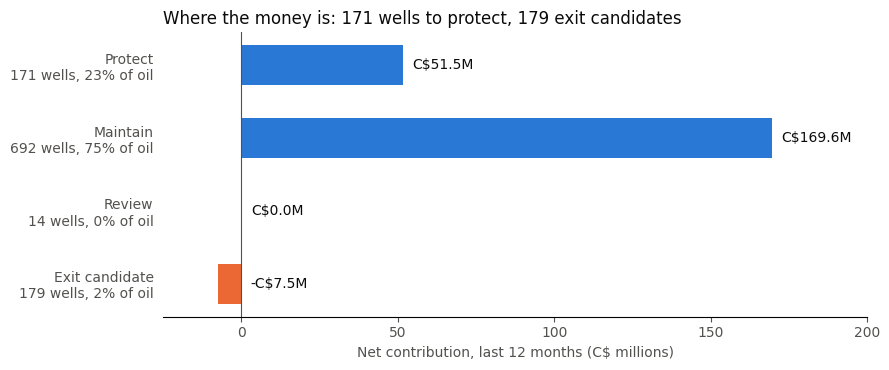

In [0]:
import matplotlib.pyplot as plt

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#9a9992", "#0b0b0b", "#52514e"

def tidy(ax):
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(left=False, colors=MUTED)

tt = (sc.groupby("tier").agg(wells=("uwi", "count"), bbl=("bbl", "sum"), net=("net", "sum"))
        .reindex(["Protect", "Maintain", "Review", "Exit candidate"]))
tt["oil_pct"] = 100 * tt.bbl / tt.bbl.sum()
names = [f"{t}\n{int(r.wells)} wells, {r.oil_pct:.0f}% of oil" for t, r in tt.iterrows()]
vals = (tt.net / 1e6).values

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names, vals, color=[BLUE if v >= 0 else ORANGE for v in vals], height=0.55)
ax.invert_yaxis()
for i, v in enumerate(vals):
    txt = f"C${abs(v):,.1f}M" if abs(v) < 0.05 else (f"C${v:,.1f}M" if v > 0 else f"-C${-v:,.1f}M")
    ax.text(max(v, 0) + 3, i, txt, va="center", ha="left", color=INK, fontsize=10)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlim(min(vals.min() * 1.6, -25), vals.max() * 1.18)
ax.set_xlabel("Net contribution, last 12 months (C$ millions)", color=MUTED)
ax.set_title(f"Where the money is: {int(tt.wells['Protect'])} wells to protect, {int(tt.wells['Exit candidate'])} exit candidates", loc="left", color=INK, fontsize=12)
tidy(ax); plt.tight_layout(); plt.show()

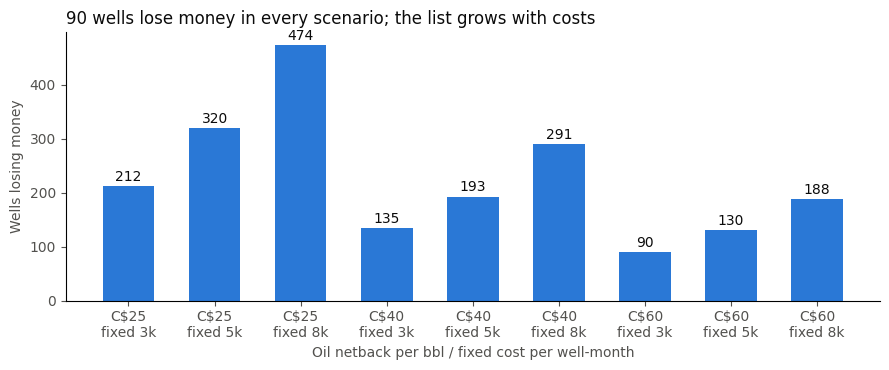

In [0]:
gp = grid.toPandas() if hasattr(grid, "toPandas") else grid
gp = gp.sort_values(["netback", "fixed_per_month"]).reset_index(drop=True)
labels = [f"C${int(r.netback)}\nfixed {int(r.fixed_per_month)/1000:.0f}k" for r in gp.itertuples()]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(labels, gp.wells_negative, color=BLUE, width=0.6)
for i, v in enumerate(gp.wells_negative):
    ax.text(i, v + gp.wells_negative.max() * 0.02, int(v), ha="center", color=INK, fontsize=10)
ax.set_ylabel("Wells losing money", color=MUTED)
ax.set_xlabel("Oil netback per bbl / fixed cost per well-month", color=MUTED)
ax.set_title(f"{int(gp.wells_negative.min())} wells lose money in every scenario; the list grows with costs", loc="left", color=INK, fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(colors=MUTED); plt.tight_layout(); plt.show()

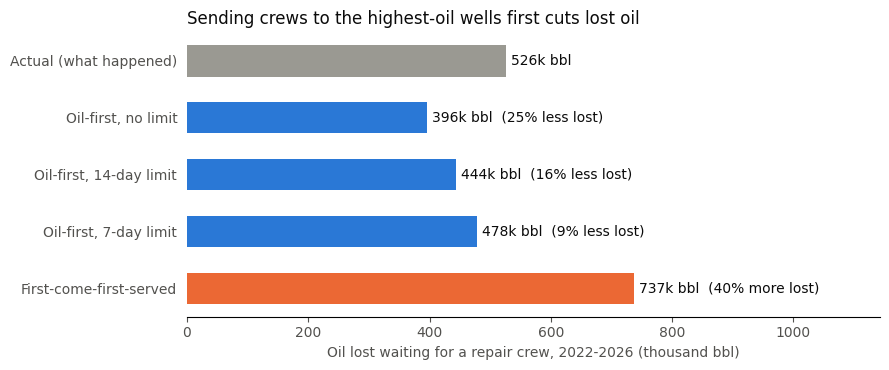

In [0]:
d = disp.copy()
names = [p.replace("Highest-oil-first", "Oil-first") for p in d.policy]
cols = [GREY, BLUE, BLUE, BLUE, ORANGE]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names, d.lost_kbbl, color=cols, height=0.55)
ax.invert_yaxis()
for i, r in enumerate(d.itertuples()):
    note = "" if i == 0 else (f"  ({r.saving_pct:.0f}% less lost)" if r.saving_pct > 0 else f"  ({-r.saving_pct:.0f}% more lost)")
    ax.text(r.lost_kbbl + 8, i, f"{r.lost_kbbl:,.0f}k bbl{note}", va="center", color=INK, fontsize=10)
ax.set_xlim(0, d.lost_kbbl.max() * 1.55)
ax.set_xlabel("Oil lost waiting for a repair crew, 2022-2026 (thousand bbl)", color=MUTED)
ax.set_title("Sending crews to the highest-oil wells first cuts lost oil", loc="left", color=INK, fontsize=12)
tidy(ax); plt.tight_layout(); plt.show()